---
# title: "My Notebook"
format:
  html:
    toc: true           # ✅ Table of contents (outline)
    toc-location: left  # ✅ Place TOC in the left sidebar
    number-sections: true
    code-fold: true
    code-summary: "Show Code"
    theme: cosmo        # Optional themes: cosmo, flatly, default, etc.
---

# Week 8A<br/>Geospatial Data: Street Networks


In [26]:
# The usual imports
import altair as alt
import geopandas as gpd
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [27]:
# Show all columns in dataframes
pd.options.display.max_columns = 999

# Hide warnings due to issue in shapely package 
# See: https://github.com/shapely/shapely/issues/1345
np.seterr(invalid="ignore")

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Today: Urban street networks and OpenStreetMap (OSM)

- Two tools that make working with OSM data very easy
- What kind of questions can we answer?
    - Street orientations 
    - Mapping event points to streets: car crashes
    - Mapping amenities
    - Network-constrained distances: accessibility

## OSM: what is it?

- Collaborative mapping
- A free editable map of the World
- Sort of like Wikipedia for maps

**Great source of data: street networks and a wealth of amenity information**

https://www.openstreetmap.org

## Working with OSM data

- Raw data is very messy
- Two relatively new, amazing Python packages greatly simply the process
- Related, but complementary features    
    - **OSMnx:** downloading and manipulating streets as networks
    - **Pandana:** networks focused on accessibility of amenities
    
**Related:** interactive web maps in Python

## Part 1: OSMnx

Relatively new package (just a few years old), but quickly becoming the go to package for working with street networks and OpenStreetMap data in Python.

Several key features: 

- Downloading political boundaries for cities, states, countries, etc
- Downloading street networks
- Analyzing networks: routing, visualization, statistics

  - [GitHub](https://github.com/gboeing/osmnx)
  - [Introductory Blog Post](https://geoffboeing.com/2016/11/osmnx-python-street-networks/)
  - [Jupyter Notebook Examples](https://github.com/gboeing/osmnx-examples/tree/master/notebooks) ([Binder](https://mybinder.org/v2/gh/gboeing/osmnx-examples/main?urlpath=/tree/notebooks))
  - [Documentation](https://osmnx.readthedocs.io)

In [28]:
# !pip install osmnx

In [29]:
import osmnx as ox

### 1.1. Getting boundary shapefiles from OSM

Key function: `geocode_to_gdf()` ([docs](https://osmnx.readthedocs.io/en/stable/osmnx.html#osmnx.geocoder.geocode_to_gdf))

We can get the boundary for anything identified as a "place" by OSM.

**Important: Be careful to pass the right place name that OSM needs**

In [30]:
philly = ox.geocode_to_gdf("Philadelphia, PA")

philly.head()

,geometry,bbox_west,bbox_south,bbox_east,bbox_north,place_id,osm_type,osm_id,lat,lon,class,type,place_rank,importance,addresstype,name,display_name
0,"POLYGON ((-75.28027 39.97496, -75.28023 39.974...",-75.280266,39.867005,-74.955831,40.137959,331386626,relation,188022,39.952724,-75.163526,boundary,administrative,16,0.766493,city,Philadelphia,"Philadelphia, Philadelphia County, Pennsylvani..."


In [31]:
philly.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

We can plot it just like any other GeoDataFrame

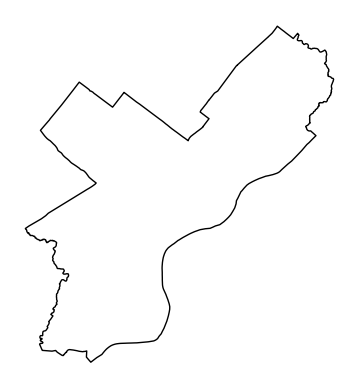

In [32]:
# Project it to Web Mercator first and plot
ax = philly.to_crs(epsg=3857).plot(facecolor="none", edgecolor="black")
ax.set_axis_off()

### 1.2 Projecting with OSMnx

Key function: `project_gdf()` ([docs](https://osmnx.readthedocs.io/en/stable/osmnx.html#osmnx.projection.project_gdf))

Automatically projects to the [Universal Transverse Mercator](https://en.wikipedia.org/wiki/Universal_Transverse_Mercator_coordinate_system) (UTM) CRS for the UTM zone that the centroid of the polygon lies in 

A good, general projection that works for most latitudes except very northern locations.

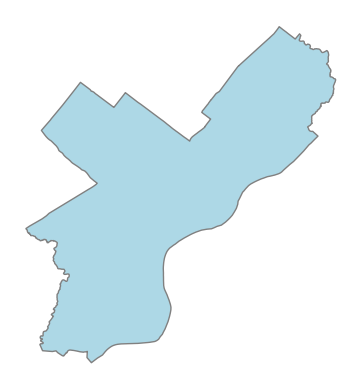

In [33]:
# ax = ox.project_gdf(philly).plot(fc="lightblue", ec="gray")
# ax.set_axis_off()

import geopandas as gpd

# Reproject philly to its best UTM zone
philly_proj = philly.to_crs(philly.estimate_utm_crs())

# Plot
ax = philly_proj.plot(fc="lightblue", ec="gray")
ax.set_axis_off()


Some more examples:

In [34]:
# Some examples
place1 = ox.geocode_to_gdf("Manhattan, New York City, New York, USA")
place2 = ox.geocode_to_gdf("Miami-Dade County, Florida")
place3 = ox.geocode_to_gdf("Florida, USA")
place4 = ox.geocode_to_gdf("Spain")

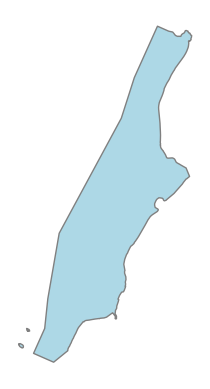

In [35]:
# # Manhattan
# ax = ox.project_gdf(place1).plot(fc="lightblue", ec="gray")
# ax.set_axis_off()

# Reproject philly to its best UTM zone
place1_repoj = place1.to_crs(place1.estimate_utm_crs())
ax = place1_repoj.plot(fc="lightblue", ec="gray")
ax.set_axis_off()

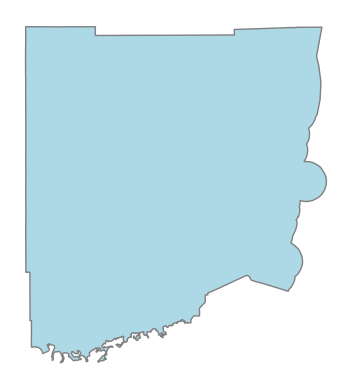

In [36]:
# # Miami-Dade County
# ax = ox.project_gdf(place2).plot(fc="lightblue", ec="gray")
# ax.set_axis_off()

# Reproject philly to its best UTM zone
place2_repoj = place2.to_crs(place2.estimate_utm_crs())
ax = place2_repoj.plot(fc="lightblue", ec="gray")
ax.set_axis_off()

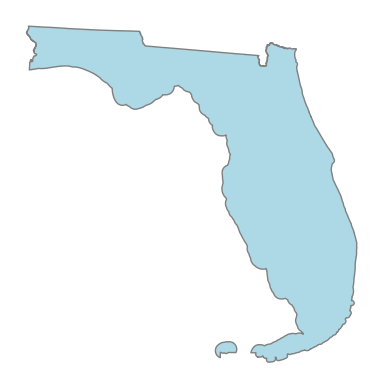

In [37]:
# # Florida
# ax = ox.project_gdf(place3).plot(fc="lightblue", ec="gray")
# ax.set_axis_off()

# Reproject philly to its best UTM zone
place3_repoj = place3.to_crs(place3.estimate_utm_crs())
ax = place3_repoj.plot(fc="lightblue", ec="gray")
ax.set_axis_off()

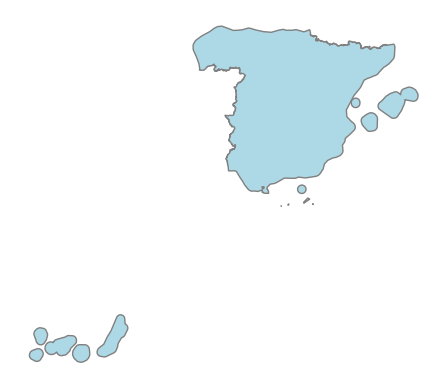

In [38]:
# # Spain
# ax = ox.project_gdf(place4).plot(fc="lightblue", ec="gray")
# ax.set_axis_off()

# Reproject philly to its best UTM zone
place4_repoj = place4.to_crs(place4.estimate_utm_crs())
ax = place4_repoj.plot(fc="lightblue", ec="gray")
ax.set_axis_off()

### 1.3 Downloading OSM features

Key functions: `features_from_*`

- `features_from_place()` ([docs](https://osmnx.readthedocs.io/en/stable/osmnx.html#osmnx.features.features_from_place))
     - Download features within an OSM place boundary
- `features_from_address()` ([docs](https://osmnx.readthedocs.io/en/stable/osmnx.html#osmnx.features.features_from_address))
    - Download features within a certain distance of an address
- `features_from_bbox()` ([docs](https://osmnx.readthedocs.io/en/stable/osmnx.html#osmnx.features.features_from_bbox))
    - Download features within a N, S, E, W bounding box
- `features_from_point()` ([docs](https://osmnx.readthedocs.io/en/stable/osmnx.html#osmnx.features.features_from_point)) 
    - Download features within a certain distance of a specified point
- `features_from_polygon()` ([docs](https://osmnx.readthedocs.io/en/stable/osmnx.html#osmnx.features.features_from_polygon))
    - Download features within a polygon object

::: {.callout-note}
### About OSM features

**Important reference:** https://wiki.openstreetmap.org/wiki/Map_Features

- OSM uses a *tagging* system to categorize different map features
- The main feature categories are available on the OSM Wikipedia
    - Examples: 'amenity', 'building', 'landuse', 'highway'
- There are specific sub-categories for each feature type too:
    - Amenity examples: 'bar', 'college', 'library'

In the language of OSM, the "key" is the main feature category (e.g., amenity) and the "value" is the sub-category type (e.g., "bar")
:::

`osmnx` mirrors the key/value syntax of OSM. Use a dict to specify the features you want: 

In [39]:
# Get all amenities in Philadelphia
amenities = ox.features_from_place("Philadelphia, PA", tags={"amenity": True})

In [40]:
len(amenities)

15759

In [41]:
amenities.head()

geometry           amenity      brand  \
element id                                                                   
node    109811385  POINT (-75.19487 40.05846)             bench        NaN   
        110237774   POINT (-75.15662 39.9504)  parking_entrance        NaN   
        274216093  POINT (-75.19125 39.95764)               atm   Citibank   
        274217596  POINT (-75.19229 39.95301)              cafe  Starbucks   
        313440966  POINT (-75.16694 39.96394)       car_sharing        NaN   

                  brand:wikidata       name  operator operator:wikidata  \
element id                                                                
node    109811385            NaN        NaN       NaN               NaN   
        110237774            NaN        NaN       NaN               NaN   
        274216093        Q857063   Citibank  Citibank           Q857063   
        274217596         Q37158  Starbucks       NaN               NaN   
        313440966            NaN        NaN       NaN               NaN   

                  operator:wikipedia short_name     addr:city  \
element id                                                      
node    109811385                NaN        NaN           NaN   
        110237774                NaN        NaN           NaN   
        274216093        en:Citibank       Citi           NaN   
        274217596                NaN        NaN  Philadelphia   
        313440966                NaN        NaN           NaN   

                  addr:housenumber addr:postcode addr:state    addr:street  \
element id                                                                   
node    109811385              NaN           NaN        NaN            NaN   
        110237774              NaN           NaN        NaN            NaN   
        274216093              NaN           NaN        NaN            NaN   
        274217596             3401         19104         PA  Walnut Street   
        313440966              NaN           NaN        NaN            NaN   

                  air_conditioning         branch      cuisine  \
element id                                                       
node    109811385              NaN            NaN          NaN   
        110237774              NaN            NaN          NaN   
        274216093              NaN            NaN          NaN   
        274217596              yes  Walnut & 34th  coffee_shop   
        313440966              NaN            NaN          NaN   

                      official_name                         opening_hours  \
element id                                                                  
node    109811385               NaN                                   NaN   
        110237774               NaN                                   NaN   
        274216093               NaN                                   NaN   
        274217596  Starbucks Coffee  Mo-Fr 05:30-20:00; Sa,Su 06:00-20:00   
        313440966               NaN                                   NaN   

                             phone    ref takeaway  \
element id                                           
node    109811385              NaN    NaN      NaN   
        110237774              NaN    NaN      NaN   
        274216093              NaN    NaN      NaN   
        274217596  +1-215-387-1914  14716      yes   
        313440966              NaN    NaN      NaN   

                                                             website  \
element id                                                             
node    109811385                                                NaN   
        110237774                                                NaN   
        274216093                                                NaN   
        274217596  https://www.starbucks.com/store-locator/store/...   
        313440966                                                NaN   

                       created_by           source alt_name  atm  \
elemen

In [42]:
# Get all bars in philadelphia
bars = ox.features_from_place("Philadelphia, PA", tags={"amenity": "bar"})

In [43]:
len(bars)

165

In [44]:
bars.head()

geometry addr:housenumber  \
element id                                                        
node    1033935437  POINT (-75.17552 39.95242)             2101   
        1167079387   POINT (-75.14925 39.9417)              401   
        1204761128  POINT (-75.16363 39.92685)              NaN   
        1424271155  POINT (-75.14909 39.94152)              344   
        1475230378  POINT (-75.14002 39.96627)             1001   

                         addr:street amenity    contact:phone  \
element id                                                      
node    1033935437   Chestnut Street     bar  +1 215-568-3355   
        1167079387      South Street     bar  +1 215-925-6455   
        1204761128               NaN     bar              NaN   
        1424271155      South Street     bar              NaN   
        1475230378  North 2nd Street     bar              NaN   

                                                      contact:website  \
element id                                                              
node    1033935437  https://mixbarandgrillphilly.com/location/mix-...   
        1167079387                 https://www.milkboy.tv/southstreet   
        1204761128                                                NaN   
        1424271155                                                NaN   
        1475230378                                                NaN   

                                                      description  \
element id                                                          
node    1033935437  The bar is open until whenever the rush ends.   
        1167079387                                            NaN   
        1204761128                                            NaN   
        1424271155                                            NaN   
        1475230378                                            NaN   

                                        name  \
element id                                     
node    1033935437           Mix Bar & Grill   
        1167079387      MilkBoy South Street   
        1204761128  Vikings High School Club   
        1424271155                Copabanana   
        1475230378              Gunner's Run   

                                              opening_hours outdoor_seating  \
element id                                                                    
node    1033935437  Mo-We,Su 11:00-22:00; Th-Sa 11:00-23:00             yes   
        1167079387  Mo-Tu,Su 11:00-24:00; We-Sa 11:00-25:00             NaN   
        1204761128                                      NaN             NaN   
        1424271155                        Mo-Su 11:30-02:00             NaN   
        1475230378                        Mo-Su 11:00-02:00             NaN   

                    check_date                             contact:facebook  \
element id                                                                    
node    1033935437         NaN                                          NaN   
        1167079387  2023-04-12  https://www.facebook.com/milkboysouthstreet   
        1204761128         NaN                                          NaN   
        1424271155         NaN                                          NaN   
        1475230378         NaN                                          NaN   

                   addr:postcode            phone                  website  \
element id                                                                   
node    1033935437           NaN              NaN                      NaN   
        1167079387           NaN              NaN                      NaN   
        1204761128           NaN              NaN                      NaN   
        1424271155         19147  +1 215-923-6180  https://copabanana.com/   
        1475230378         19123  +1 215-923-4600   http://gunnersrun.com/   

                       addr:city air_conditioning smoking toilets:wheelchair  \
element id                                  

In [45]:
# Get bar, pub, and restaurant features in Philadelphia
food_and_drink = ox.features_from_place(
    "Philadelphia, PA", tags={"amenity": ["pub", "bar", "restaurant"]}
)

In [46]:
len(food_and_drink)

1157

In [47]:
food_and_drink.head()

geometry     addr:city addr:housenumber  \
element id                                                                     
node    333786044  POINT (-75.15893 39.94086)  Philadelphia              735   
        343293806  POINT (-75.15946 39.96073)  Philadelphia              501   
        566683522  POINT (-75.15755 39.96205)  Philadelphia             1139   
        596230881  POINT (-75.18682 40.05492)           NaN              NaN   
        596245658   POINT (-75.19035 40.0592)  Philadelphia             7136   

                  addr:postcode addr:state           addr:street  \
element id                                                         
node    333786044         19147         PA     South 10th Street   
        343293806         19123         PA     North 13th Street   
        566683522         19123        NaN  Spring Garden Street   
        596230881           NaN        NaN                   NaN   
        596245658         19119         PA     Germantown Avenue   

                              alt_name     amenity  atm  \
element id                                                
node    333786044  Morning Glory Diner  restaurant  yes   
        343293806                  NaN         pub  NaN   
        566683522                  NaN  restaurant  NaN   
        596230881                  NaN  restaurant  NaN   
        596245658                  NaN  restaurant  NaN   

                                              contact:facebook  \
element id                                                       
node    333786044  https://www.facebook.com/MorningGloryDiner/   
        343293806                                          NaN   
        566683522                                          NaN   
        596230881                                          NaN   
        596245658                                          NaN   

                                                   cuisine diet:vegetarian  \
element id                                                                   
node    333786044                                    diner             yes   
        343293806  american;burger;fish_and_chips;sandwich             yes   
        566683522                                    pizza             NaN   
        596230881                                      NaN             NaN   
        596245658                                      NaN             NaN   

                                               name  \
element id                                            
node    333786044               Sam's Morning Glory   
        343293806               Prohibition Taproom   
        566683522  Spring Garden Pizza & Restaurant   
        596230881                               NaN   
        596245658             Earth Bread & Brewery   

                                                       opening_hours  \
element id                                                             
node    333786044               Mo-Fr 08:00-14:00; Sa,Su 08:00-15:00   
        343293806  Fr-Sa 12:00-01:00; Su 12:00-00:00; Mo-Th 16:00...   
        566683522          Mo-Fr 08:00-20:00; Sa 08:00-17:00; Su off   
        596230881                                                NaN   
        596245658                                                NaN   

                  payment:cash payment:credit_cards payment:debit_cards  \
element id                                                                
node    333786044          yes                   no                  no   
        343293806          NaN                  NaN                 NaN   
        566683522          NaN                  NaN                 NaN   
        596230881          NaN                  NaN                 NaN   
        596245658          NaN                  NaN                 NaN   

                             source wheelchair brewery    contact:instagram  \
element id                                                                    


In [48]:
# Get bus stop features
bus_stops = ox.features_from_place("Philadelphia, PA", tags={"highway": "bus_stop"})

In [49]:
len(bus_stops)

334

In [50]:
bus_stops.head()

geometry bench  bus covered   highway  \
element id                                                                    
node    361011456   POINT (-75.16166 39.95223)   yes  yes     yes  bus_stop   
        750281693   POINT (-75.07732 40.01797)   NaN  yes     NaN  bus_stop   
        768271130   POINT (-75.20726 40.01487)   NaN  yes     NaN  bus_stop   
        1015342921   POINT (-75.18187 39.9664)   NaN  yes     NaN  bus_stop   
        1015342926   POINT (-75.18024 39.9667)   NaN  yes     NaN  bus_stop   

                                                 name network  \
element id                                                      
node    361011456                 13th St & Market St   SEPTA   
        750281693                                 NaN     NaN   
        768271130   Wissahickon Transportation Center   SEPTA   
        1015342921                                NaN     NaN   
        1015342926                                NaN     NaN   

                   network:wikidata operator public_transport    ref shelter  \
element id                                                                     
node    361011456          Q2037863    SEPTA         platform  10264     yes   
        750281693               NaN      NaN         platform    NaN     NaN   
        768271130          Q2037863    SEPTA         platform    NaN     yes   
        1015342921              NaN      NaN         platform    NaN     NaN   
        1015342926              NaN      NaN         platform    NaN     NaN   

                   network:wikipedia tactile_paving wheelchair route_ref  \
element id                                                                 
node    361011456                NaN            NaN        NaN       NaN   
        750281693                NaN            NaN        NaN       NaN   
        768271130                NaN            NaN        NaN       NaN   
        1015342921               NaN            NaN        NaN       NaN   
        1015342926               NaN            NaN        NaN       NaN   

                   local_ref  bin  lit designation source check_date:shelter  \
element id                                                                     
node    361011456        NaN  NaN  NaN         NaN    NaN                NaN   
        750281693        NaN  NaN  NaN         NaN    NaN                NaN   
        768271130        NaN  NaN  NaN         NaN    NaN                NaN   
        1015342921       NaN  NaN  NaN         NaN    NaN                NaN   
        1015342926       NaN  NaN  NaN         NaN    NaN                NaN   

                   departures_board internet_access addr:street route_ref_1  \
element id                                                                    
node    361011456               NaN             NaN         NaN         NaN   
        750281693               NaN             NaN         NaN         NaN   
        768271130               NaN             NaN         NaN         NaN   
        1015342921              NaN             NaN         NaN         NaN   
        1015342926              NaN             NaN         NaN         NaN   

                   operator:wikidata description note brand brand:wikidata  \
element id                                                                   
node    361011456                NaN         NaN  NaN   NaN            NaN   
        750281693                NaN         NaN  NaN   NaN            NaN   
        768271130                NaN         NaN  NaN   NaN            NaN   
        1015342921               NaN         NaN  NaN   NaN            NaN   
        1015342926               NaN         NaN  NaN   NaN            NaN   

                   railway tram trolleybus network:short not:network:wikidata  \
element id                                                                      
node    361011456      NaN  NaN        NaN           NaN                  NaN   
        750281693      NaN  N

In [51]:
# Get commercial and retail landuse features
landuse = ox.features_from_place(
    "Philadelphia, PA", tags={"landuse": ["commercial", "retail"]}
)

In [52]:
len(landuse)

349

Let's plot the land use features:

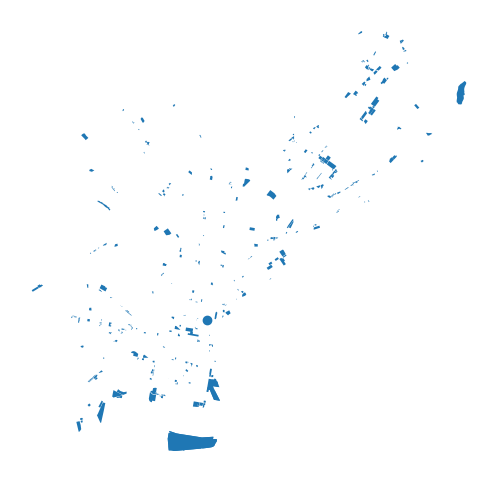

In [53]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

ax = landuse.plot(ax=ax)
ax.set_axis_off()

### 1.4 Downloading street networks

Key functions: `graph_from_*` 

- `graph_from_place()` ([docs](https://osmnx.readthedocs.io/en/stable/osmnx.html#osmnx.graph.graph_from_place))
     - Download street network within an OSM place boundary
- `graph_from_address()` ([docs](https://osmnx.readthedocs.io/en/stable/osmnx.html#osmnx.graph.graph_from_address))
    - Download street network within a certain distance of an address
- `graph_from_bbox()` ([docs](https://osmnx.readthedocs.io/en/stable/osmnx.html#osmnx.graph.graph_from_bbox))
    - Download street network within a N, S, E, W bounding box
- `graph_from_point()` ([docs](https://osmnx.readthedocs.io/en/stable/osmnx.html#osmnx.graph.graph_from_point)) 
    - Download street network within a certain distance of a specified point
- `graph_from_polygon()` ([docs](https://osmnx.readthedocs.io/en/stable/osmnx.html#osmnx.graph.graph_from_polygon))
    - Download street network within a polygon object

#### Street network around an address

Get streets within 500 meters of the center of Center City

In [54]:
G = ox.graph_from_address("Center City, Philadelphia, PA", dist=500)

Project and plot it:

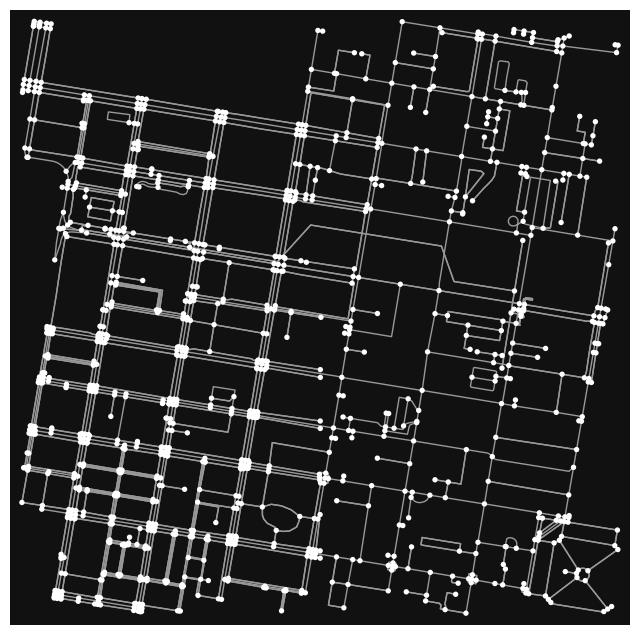

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [55]:
G_projected = ox.project_graph(G)
ox.plot_graph(G_projected)

Remove the nodes:

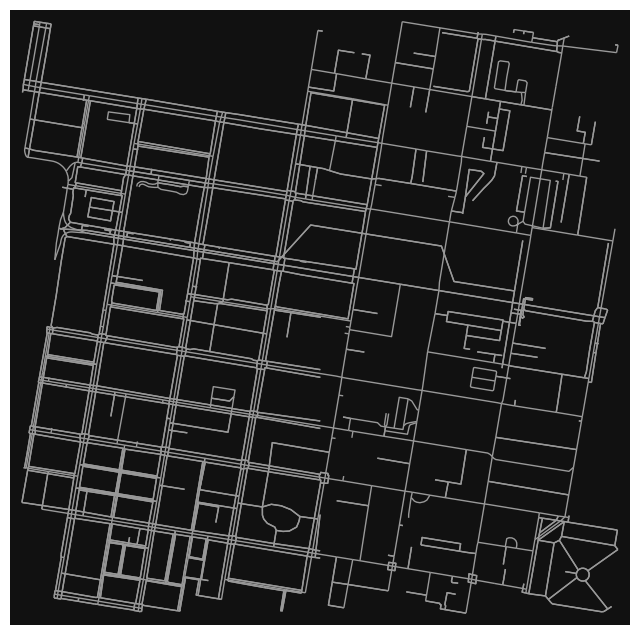

In [56]:
ox.plot_graph(G_projected, node_size=0);

Let's zoom out to 2,000 meters. This will take a little longer.

In [57]:
G = ox.graph_from_address("Center City, Philadelphia, PA", dist=2000)
G_projected = ox.project_graph(G)

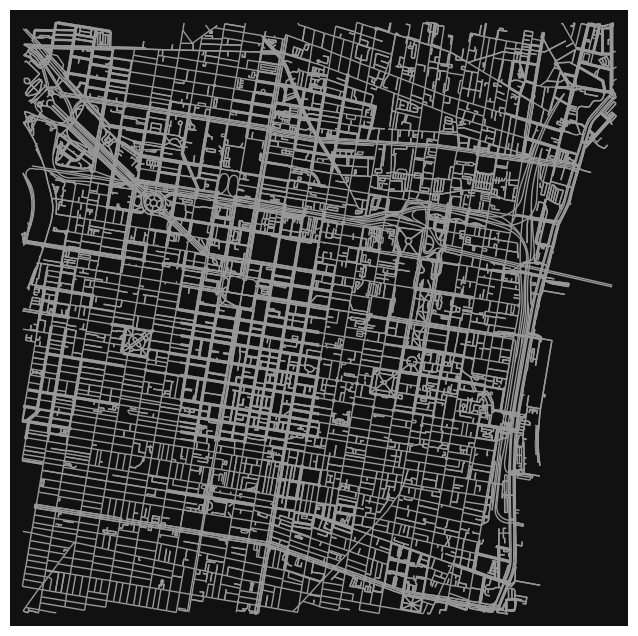

In [58]:
ox.plot_graph(G_projected, node_size=0);

#### Getting different network types

- `drive` - get drivable public streets (but not service roads)
- `drive_service` - get drivable streets, including service roads
- `walk` - get all streets and paths that pedestrians can use (this network type ignores one-way directionality)
- `bike` - get all streets and paths that cyclists can use
- `all` - download all non-private OSM streets and paths
- `all_private` - download all OSM streets and paths, including private-access ones (default)

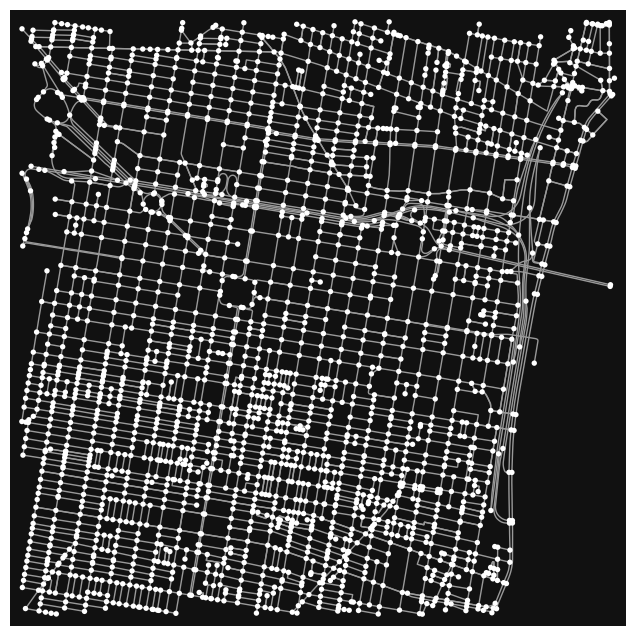

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [59]:
# the "drive" network
G = ox.graph_from_address("Center City, Philadelphia, PA", network_type="drive", dist=2000)
ox.plot_graph(G)

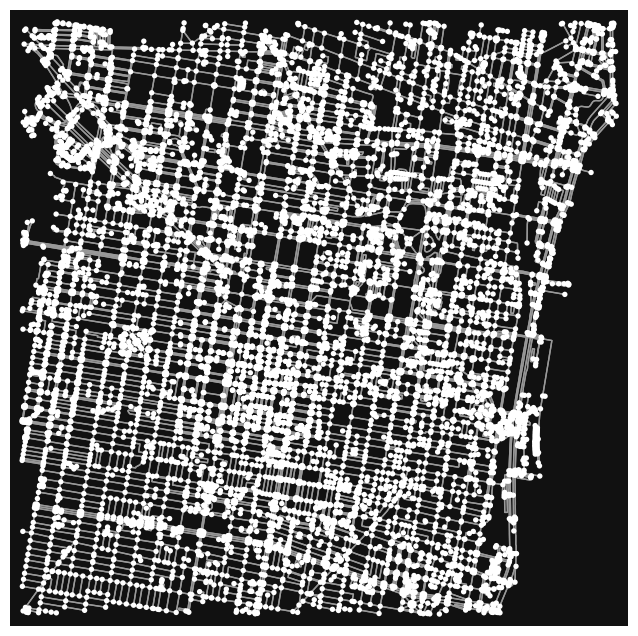

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [60]:
# the "walk" network
G = ox.graph_from_address("Center City, Philadelphia, PA", network_type="walk", dist=2000)
ox.plot_graph(ox.project_graph(G))

#### Street network within a place boundary

Use `graph_from_place()` to get the streets within a specific OSM place.

::: {.callout-caution}

A couple of things to watch out for: 
1. The place query has to be resolved by OSM.
2. If the place is a big city, you might be downloading a lot of data!

:::

Let's check out the street network for Berkeley, CA:

In [61]:
berkeley = ox.graph_from_place("Berkeley, California, USA")

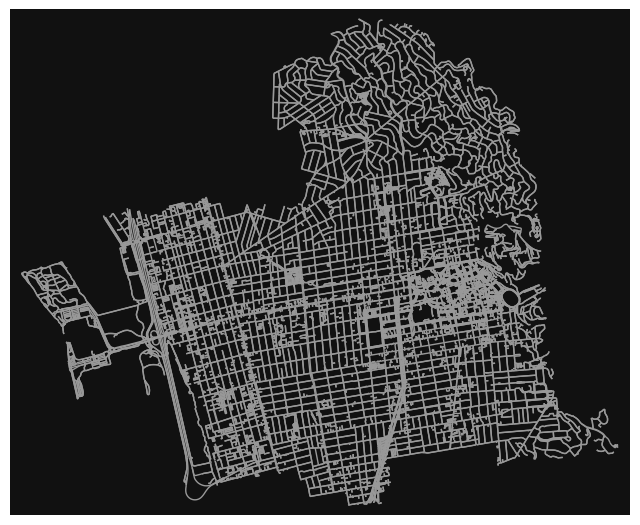

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [62]:
ox.plot_graph(ox.project_graph(berkeley), node_size=0)

#### Streets within a specific polygon

**Example:** Let's download all streets within Center City. We will use the "Central" planning district as a proxy for this area. The city's planning districts are available on [Open Data Philly](https://opendataphilly.org/datasets/planning-districts/).

In [63]:
import geopandas as gpd

planning_districts = gpd.read_file(
    "https://opendata.arcgis.com/datasets/0960ea0f38f44146bb562f2b212075aa_0.geojson"
)

In [64]:
len(planning_districts)

18

In [65]:
planning_districts.head()

,objectid,dist_name,abbrev,Shape__Area,Shape__Length,geometry
0,1,River Wards,RW,3.338947e+07,26635.524113,"POLYGON ((-75.09798 40.00496, -75.09687 40.005..."
1,2,North Delaware,NDEL,4.285306e+07,35525.335312,"POLYGON ((-74.98159 40.05363, -74.98139 40.053..."
2,3,Lower Far Northeast,LFNE,4.875252e+07,36958.071333,"POLYGON ((-74.96443 40.11728, -74.96434 40.117..."
3,4,Central,CTR,2.822133e+07,28401.823065,"POLYGON ((-75.14791 39.96733, -75.14715 39.967..."
4,5,University Southwest,USW,2.051763e+07,25957.938149,"POLYGON ((-75.18742 39.96338, -75.18644 39.963..."


Trim to the central district:

In [66]:
central_district = planning_districts.query("dist_name == 'Central'")

And plot it:

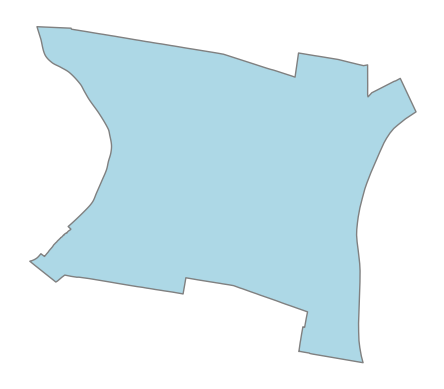

In [67]:
## old version previous OSMnx 2.0
# ax = ox.project_gdf(central_district).plot(fc="lightblue", ec="gray")
# ax.set_axis_off()

# Reproject philly to its best UTM zone
central_district_repoj = central_district.to_crs(central_district.estimate_utm_crs())
ax = central_district_repoj.plot(fc="lightblue", ec="gray")
ax.set_axis_off()

In [68]:
central_district, central_district_repoj.crs

(   objectid dist_name abbrev   Shape__Area  Shape__Length  \
 3         4   Central    CTR  2.822133e+07   28401.823065   
 
                                             geometry  
 3  POLYGON ((-75.14791 39.96733, -75.14715 39.967...  ,
 <Projected CRS: EPSG:32618>
 Name: WGS 84 / UTM zone 18N
 Axis Info [cartesian]:
 - E[east]: Easting (metre)
 - N[north]: Northing (metre)
 Area of Use:
 - name: Between 78°W and 72°W, northern hemisphere between equator and 84°N, onshore and offshore. Bahamas. Canada - Nunavut; Ontario; Quebec. Colombia. Cuba. Ecuador. Greenland. Haiti. Jamaica. Panama. Turks and Caicos Islands. United States (USA). Venezuela.
 - bounds: (-78.0, 0.0, -72.0, 84.0)
 Coordinate Operation:
 - name: UTM zone 18N
 - method: Transverse Mercator
 Datum: World Geodetic System 1984 ensemble
 - Ellipsoid: WGS 84
 - Prime Meridian: Greenwich)

Squeeze it so we can get the geometry polygon:

In [69]:
center_city_outline = central_district.squeeze().geometry

center_city_outline, type(center_city_outline)

(<POLYGON ((-75.148 39.967, -75.147 39.967, -75.147 39.969, -75.147 39.97, -7...>,
 shapely.geometry.polygon.Polygon)

Now, let's use `ox.graph_from_polygon()` to extract streets within this polygon. 

In [70]:
# Get the graph
G_cc = ox.graph_from_polygon(center_city_outline, network_type="drive")

In [23]:
# Viola!
ox.plot_graph(ox.project_graph(G_cc), node_size=0);

NameError: name 'ox' is not defined

### 1.5 Converting from a graph to a GeoDataFrame

Key function: `ox.graph_to_gdfs()` ([docs](https://osmnx.readthedocs.io/en/stable/osmnx.html?highlight=graph_to_gdf#osmnx.utils_graph.graph_to_gdfs))

You can get a GeoDataFrame for both the nodes (points) and edges (lines)

In [24]:
type(G_cc)

NameError: name 'G_cc' is not defined

In [25]:
# only get the edges
cc_edges = ox.graph_to_gdfs(G_cc, edges=True, nodes=False)

NameError: name 'ox' is not defined

In [86]:
# we have lots of data associated with each edge!
cc_edges.head()

osmid      highway lanes                   name  \
u         v         key                                                        
109727439 109911666 0    132508434  residential     1      Bainbridge Street   
109727448 109727439 0     12109011  residential   NaN  South Colorado Street   
          110034229 0     12159387  residential   NaN       Fitzwater Street   
109727507 110024052 0    193364514  residential   NaN       Carpenter Street   
109728761 110274344 0    672312336  residential   NaN           Brown Street   

                         oneway reversed      length  \
u         v         key                                
109727439 109911666 0      True    False   44.347013   
109727448 109727439 0      True    False  109.496448   
          110034229 0      True    False   91.354184   
109727507 110024052 0      True    False   53.208442   
109728761 110274344 0      True    False   58.270358   

                                                                  geometry  \
u         v         key                                                      
109727439 109911666 0    LINESTRING (-75.17104 39.94345, -75.1706 39.94...   
109727448 109727439 0    LINESTRING (-75.17125 39.94248, -75.1712 39.94...   
          110034229 0    LINESTRING (-75.17125 39.94248, -75.17129 39.9...   
109727507 110024052 0    LINESTRING (-75.17196 39.93974, -75.17134 39.9...   
109728761 110274344 0    LINESTRING (-75.17317 39.96951, -75.1725 39.96...   

                        maxspeed  ref bridge tunnel width service access  \
u         v         key                                                    
109727439 109911666 0        NaN  NaN    NaN    NaN   NaN     NaN    NaN   
109727448 109727439 0        NaN  NaN    NaN    NaN   NaN     NaN    NaN   
          110034229 0        NaN  NaN    NaN    NaN   NaN     NaN    NaN   
109727507 110024052 0        NaN  NaN    NaN    NaN   NaN     NaN    NaN   
109728761 110274344 0     25 mph  NaN    NaN    NaN   NaN     NaN    NaN   

                        junction  
u         v         key           
109727439 109911666 0        NaN  
109727448 109727439 0        NaN  
          110034229 0        NaN  
109727507 110024052 0        NaN  
109728761 110274344 0        NaN

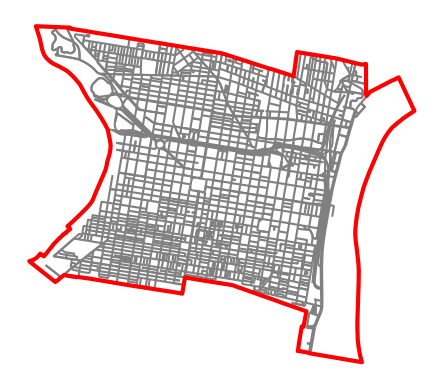

In [87]:
# plot it like any old GeoDataFrame
ax = cc_edges.to_crs(epsg=3857).plot(color="gray")

# add the neighborhood boundaries
boundary = gpd.GeoSeries([center_city_outline], crs="EPSG:4326")
boundary.to_crs(epsg=3857).plot(
    ax=ax, facecolor="none", edgecolor="red", linewidth=3, zorder=2
)

ax.set_axis_off()

**Don't forget:** We can use the `.explore()` function to get an interactive web map via Folium:

In [88]:
cc_edges.explore(tiles='cartodb positron')

### 1.6 What can we do with the graph?

- Network-based statistics
- Routing
- Street orientations
- Visualizing crashes

And much more: see the [OSMnx repository of Jupyter notebook examples](https://github.com/gboeing/osmnx-examples/tree/master/notebooks)

#### Street orientations

A [great blog post](https://geoffboeing.com/2019/09/urban-street-network-orientation/) on street orientations across different US and global cities. 

One of my favorite examples of data viz, using matplotlib for *radial histograms* of street orientations...



![](imgs/street-orientations.png){width=800}

The code for these histograms is available in [the osmnx examples repository](https://github.com/gboeing/osmnx-examples/blob/main/notebooks/17-street-network-orientations.ipynb).

#### Network statistics

We can use the `ox.basic_stats()` to get some basic network statistics

In [89]:
ox.basic_stats(G_cc)

{'n': 2097,
 'm': 4027,
 'k_avg': 3.8407248450166906,
 'edge_length_total': 357852.7307807873,
 'edge_length_avg': 88.86335504861864,
 'streets_per_node_avg': 3.407248450166905,
 'streets_per_node_counts': {0: 0,
  1: 61,
  2: 12,
  3: 1058,
  4: 949,
  5: 13,
  6: 3,
  7: 1},
 'streets_per_node_proportions': {0: 0.0,
  1: 0.029089175011921792,
  2: 0.005722460658082976,
  3: 0.5045302813543157,
  4: 0.452551263710062,
  5: 0.00619933237958989,
  6: 0.001430615164520744,
  7: 0.0004768717215069146},
 'intersection_count': 2036,
 'street_length_total': 311421.4931922978,
 'street_segment_count': 3484,
 'street_length_avg': 89.38619207586045,
 'circuity_avg': 1.0159857056912147,
 'self_loop_proportion': 0.000574052812858783}

#### Finding the shortest route

Let's calculate the shortest route between [the Art Museum](https://www.openstreetmap.org/way/28533972) and the [Liberty Bell](https://www.openstreetmap.org/node/1207480649).

We'll need to download all amenities in Philadelphia of type "tourism".

- The `ox.features_from_place()` can download OSM features with a specific tag
- You can consult the OSM pages ([the Art Museum](https://www.openstreetmap.org/way/28533972) and [Liberty Bell](https://www.openstreetmap.org/node/1207480649)) for each feature for additional info
- Both features are categorized as "tourism" in the OSM data — use the "tags" keyword to select this category

In [90]:
philly_tourism = ox.features_from_place("Philadelphia, PA", tags={"tourism": True})

In [91]:
len(philly_tourism)

928

In [92]:
philly_tourism.head()

geometry  ele gnis:feature_id  \
element id                                                           
node    357371322    POINT (-75.1958 39.9697)   17         2347097   
        360500844  POINT (-75.19582 39.95352)  NaN             NaN   
        360515304   POINT (-75.1486 39.94771)  NaN             NaN   
        360542779   POINT (-75.18932 39.9554)  NaN             NaN   
        360777728   POINT (-75.19021 39.9523)  NaN             NaN   

                                                                name  \
element id                                                             
node    357371322                              Bird Lake Picnic Area   
        360500844                                 Hilton Inn at Penn   
        360515304                                      Robert Morris   
        360542779                              Mario the Magnificent   
        360777728  Pennsylvania Historical Marker: ENIAC, first a...   

                       tourism     addr:city addr:housenumber addr:postcode  \
element id                                                                    
node    357371322  picnic_site           NaN              NaN           NaN   
        360500844        hotel  Philadelphia             3600         19104   
        360515304      artwork           NaN              NaN           NaN   
        360542779      artwork           NaN              NaN           NaN   
        360777728  information           NaN              NaN           NaN   

                  addr:state    addr:street air_conditioning   brand  \
element id                                                             
node    357371322        NaN            NaN              NaN     NaN   
        360500844         PA  Sansom Street              yes  Hilton   
        360515304        NaN            NaN              NaN     NaN   
        360542779        NaN            NaN              NaN     NaN   
        360777728        NaN            NaN              NaN     NaN   

                  brand:wikidata                   email internet_access  \
element id                                                                 
node    357371322            NaN                     NaN             NaN   
        360500844        Q598884  PHLID_Hotel@hilton.com            wlan   
        360515304            NaN                     NaN             NaN   
        360542779            NaN                     NaN             NaN   
        360777728            NaN                     NaN             NaN   

                  operator            phone  \
element id                                    
node    357371322      NaN              NaN   
        360500844   Hilton  +1-215-222-0200   
        360515304      NaN              NaN   
        360542779      NaN              NaN   
        360777728      NaN              NaN   

                                                             website  \
element id                                                             
node    357371322                                                NaN   
        360500844  https://www.hilton.com/en/hotels/phlidhh-the-i...   
        360515304                                                NaN   
        360542779                                                NaN   
        360777728                                                NaN   

                  artwork_type  historic  source   wikidata information  \
element id                                                                
node    357371322          NaN       NaN     NaN        NaN         NaN   
        360500844          NaN       NaN     NaN        NaN         NaN   
        360515304       statue  memorial  survey        NaN         NaN   
        360542779       statue       NaN     NaN  Q98563440         NaN   
        360777728          NaN       NaN     NaN        NaN       board   

                  artist_name material check_date contact:facebook  fee  \
element id   

In [104]:
# How to find the name of the POI: search for keywords
philly_tourism.loc[philly_tourism['name'].str.contains("Art", na=False)]

geometry  ele  \
element id                                                                    
node    367974278                            POINT (-75.1524 40.03748)   61   
        4064343335                          POINT (-75.22113 40.02427)  NaN   
        5368454121                          POINT (-75.19477 39.95406)  NaN   
        5718906477                          POINT (-75.13058 39.99573)  NaN   
        6639391809                          POINT (-75.16088 39.96383)  NaN   
        6680708848                          POINT (-75.16833 39.94733)  NaN   
        12188327106                         POINT (-75.14215 39.95191)  NaN   
        12193292355                          POINT (-75.14336 39.9522)  NaN   
        12222614599                         POINT (-75.14334 39.95113)  NaN   
        12235452452                         POINT (-75.14486 39.95339)  NaN   
way     28533972     POLYGON ((-75.18117 39.96468, -75.18141 39.964...   32   
        333931830    POLYGON ((-75.1641 39.95543, -75.16416 39.9551...   13   
        988345364    POLYGON ((-75.21926 40.0832, -75.21931 40.0832...   84   

                    gnis:feature_id                                   name  \
element id                                                                   
node    367974278           2349240         La Salle University Art Museum   
        4064343335              NaN        Soft Illusions Fine Art Gallery   
        5368454121              NaN          Institute of Contemporary Art   
        5718906477              NaN             Art Making Machine Studios   
        6639391809              NaN      Philadelphia Museum of Jewish Art   
        6680708848              NaN               Romanian Folk Art Museum   
        12188327106             NaN                        Arch Enemy Arts   
        12193292355             NaN                      Twelve Gates Arts   
        12222614599             NaN          Larry Becker Contemporary Art   
        12235452452             NaN                 Museum for Art in Wood   
way     28533972                NaN                Philadelphia Art Museum   
        333931830           1196718  Pennsylvania Academy of the Fine Arts   
        988345364               NaN                    Woodmere Art Museum   

                     tourism     addr:city addr:housenumber addr:postcode  \
element id                                                                  
node    367974278     museum  Philadelphia             1900           NaN   
        4064343335   gallery  Philadelphia             4226         19127   
        5368454121    museum  Philadelphia              118         19104   
        5718906477   gallery  Philadelphia             3000         19133   
        6639391809    museum  Philadelphia              615         19123   
        6680708848    museum  Philadelphia             1606         19103   
        12188327106  gallery  Philadelphia              109         19106   
        12193292355  gallery  Philadelphia              106         19106   
        12222614599  gallery  Philadelphia               43         19106   
        12235452452   museum  Philadelphia              141         19106   
way     28533972      museum  Philadelphia             2600         19130   
        333931830     museum  Philadelphia              118         19102   
        988345364     museum  Philadelphia             9201         19118   

                    addr:state                addr:street air_conditioning  \
element id                                                                   
node    367974278           PA          West Olney Avenue              NaN   
        4064343335          PA                Main Street              NaN   
        5368454121          PA          South 36th Street              NaN   
        5718906477          PA                Hope Street              NaN   
        6639391809          PA         North Broad Street              NaN   
   

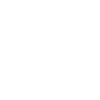

In [107]:
art_museum = philly_tourism.query("name == 'Philadelphia Art Museum'").squeeze()

art_museum.geometry

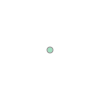

In [108]:
liberty_bell = philly_tourism.query("name == 'Liberty Bell'").squeeze()

liberty_bell.geometry

Now, extract the lat and lng coordinates

For the Art Museum geometry, we can use the `.geometry.centroid` attribute to calculate the centroid of the building footprint. 

In [109]:
liberty_bell_x = liberty_bell.geometry.x
liberty_bell_y = liberty_bell.geometry.y

In [110]:
art_museum_x = art_museum.geometry.centroid.x
art_museum_y = art_museum.geometry.centroid.y

Find the nearest nodes on our OSMnx graph, using the `ox.nearest_nodes()` function


In [62]:
ox.nearest_nodes?

Signature: ox.nearest_nodes(G, X, Y, return_dist=False)
Docstring:
Find the nearest node to a point or to each of several points.

If `X` and `Y` are single coordinate values, this will return the nearest
node to that point. If `X` and `Y` are lists of coordinate values, this
will return the nearest node to each point.

If the graph is projected, this uses a k-d tree for euclidean nearest
neighbor search, which requires that scipy is installed as an optional
dependency. If it is unprojected, this uses a ball tree for haversine
nearest neighbor search, which requires that scikit-learn is installed as
an optional dependency.

Parameters
----------
G : networkx.MultiDiGraph
    graph in which to find nearest nodes
X : float or list
    points' x (longitude) coordinates, in same CRS/units as graph and
    containing no nulls
Y : float or list
    points' y (latitude) coordinates, in same CRS/units as graph and
    containing no nulls
return_dist : bool
    optionally also return distance b

In [111]:
art_museum_y

39.9656755285648

In [112]:
# Get the origin node
orig_node = ox.nearest_nodes(G_cc, liberty_bell_x, liberty_bell_y) 

# Get the destination node
dest_node = ox.nearest_nodes(G_cc, art_museum_x, art_museum_y)

Now, we can use `ox.shortest_path()` function to find the shortest path between these graph nodes.

::: {.callout-note}
We need to specify weight='length' to find the shortest path by minimizing distance traveled (otherwise it treats each edge as weight=1).
:::

In [115]:
# get the shortest path --> just a list of node IDs
route1 = ox.shortest_path(G_cc, orig_node, dest_node, weight="length")

route1

[3408446156,
 110217312,
 3425012161,
 109814427,
 5372039288,
 109814445,
 109814449,
 5358069713,
 5372059864,
 2644235371,
 5534891499,
 110540235,
 109750941,
 110402209,
 110402230,
 534960802,
 110391250,
 637791907,
 637791980,
 110329803,
 110329806,
 775897224,
 3414249481,
 110329822,
 110391452,
 110353061,
 11162290432,
 110054089,
 775897147,
 110329848,
 110329851,
 110125895,
 534969088,
 109745905,
 109740423,
 110330569,
 550175399]

Use `ox.plot_graph_route()` to plot a graph and highlight a specific route

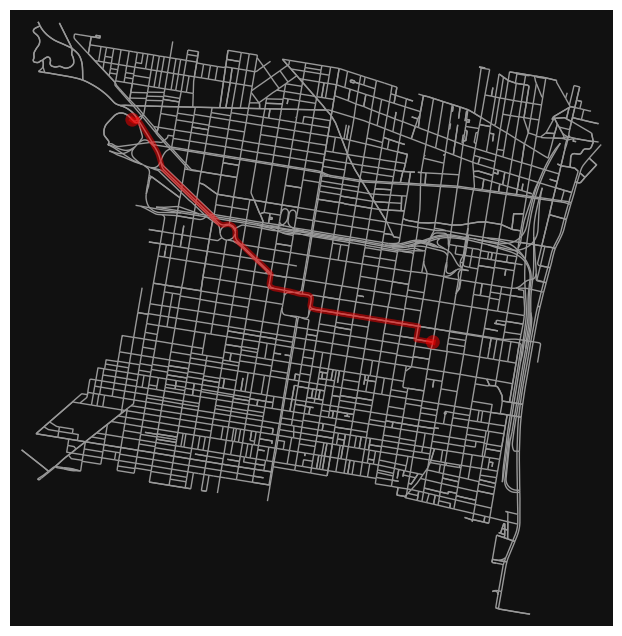

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [117]:
ox.plot_graph_route(G_cc, route1, node_size=0)

How about an interactive version?

`osmnx` has a helper function `ox.utils_graph.route_to_gdf()` to convert a route to a GeoDataFrame of edges.

In [118]:
# ox.utils_graph.route_to_gdf(G_cc, route1, weight="length").explore(
#     tiles="cartodb positron",
#     color="red",
# )

## new OSMnx 2.0 version
import osmnx as ox

# New import location
from osmnx import routing
# Convert route to GeoDataFrame
gdf_route = routing.route_to_gdf(G_cc, route1, weight="length")

# Explore with folium/leafmap
gdf_route.explore(
    tiles="cartodb positron",
    color="red"
)

#### Finding the shortest travel time


The `add_edge_speeds` function add edge speeds (km per hour) to graph as new `speed_kph` edge attributes. 

The function will add free-flow travel speeds for all edges based on the average `maxspeed` value of edges, per highway type. This process can definitely be imprecise, but in the case that you happen to have more precise speed data, you can supply your own data instead of relying on OSM data. 

In [119]:
# impute speed on all edges missing data
G_cc = ox.add_edge_speeds(G_cc)

# calculate travel time (seconds) for all edges
G_cc = ox.add_edge_travel_times(G_cc)

In [120]:
# Get the graph edges
edges = ox.graph_to_gdfs(G_cc, nodes=False)

In [121]:
edges.head()

osmid      highway lanes                   name  \
u         v         key                                                        
109727439 109911666 0    132508434  residential     1      Bainbridge Street   
109727448 109727439 0     12109011  residential   NaN  South Colorado Street   
          110034229 0     12159387  residential   NaN       Fitzwater Street   
109727507 110024052 0    193364514  residential   NaN       Carpenter Street   
109728761 110274344 0    672312336  residential   NaN           Brown Street   

                         oneway reversed      length  \
u         v         key                                
109727439 109911666 0      True    False   44.347013   
109727448 109727439 0      True    False  109.496448   
          110034229 0      True    False   91.354184   
109727507 110024052 0      True    False   53.208442   
109728761 110274344 0      True    False   58.270358   

                                                                  geometry  \
u         v         key                                                      
109727439 109911666 0    LINESTRING (-75.17104 39.94345, -75.1706 39.94...   
109727448 109727439 0    LINESTRING (-75.17125 39.94248, -75.1712 39.94...   
          110034229 0    LINESTRING (-75.17125 39.94248, -75.17129 39.9...   
109727507 110024052 0    LINESTRING (-75.17196 39.93974, -75.17134 39.9...   
109728761 110274344 0    LINESTRING (-75.17317 39.96951, -75.1725 39.96...   

                         speed_kph  travel_time maxspeed  ref bridge tunnel  \
u         v         key                                                       
109727439 109911666 0    38.467115     4.150279      NaN  NaN    NaN    NaN   
109727448 109727439 0    38.467115    10.247382      NaN  NaN    NaN    NaN   
          110034229 0    38.467115     8.549512      NaN  NaN    NaN    NaN   
109727507 110024052 0    38.467115     4.979588      NaN  NaN    NaN    NaN   
109728761 110274344 0    40.233500     5.213896   25 mph  NaN    NaN    NaN   

                        width service access junction  
u         v         key                                
109727439 109911666 0     NaN     NaN    NaN      NaN  
109727448 109727439 0     NaN     NaN    NaN      NaN  
          110034229 0     NaN     NaN    NaN      NaN  
109727507 110024052 0     NaN     NaN    NaN      NaN  
109728761 110274344 0     NaN     NaN    NaN      NaN

In [122]:
# Groupby highway type and get the mean values
edges["highway"] = edges["highway"].astype(str)
edges.groupby("highway")[["length", "speed_kph", "travel_time"]].mean()

,length,speed_kph,travel_time
highway,,,
"['motorway_link', 'secondary_link']",224.673048,40.233500,20.103222
"['residential', 'unclassified']",258.436611,40.233500,23.124307
"['tertiary', 'motorway_link']",151.598640,40.233500,13.564694
living_street,52.876864,45.884028,4.148649
motorway,446.906218,82.720076,19.204545
motorway_link,309.892510,40.233500,27.728461
primary,102.958582,44.388523,8.381328
primary_link,53.891964,40.233500,4.822128
residential,80.963002,38.465687,7.603245


In [123]:
# calculate two routes by minimizing travel time
route2 = ox.shortest_path(G_cc, orig_node, dest_node, weight="travel_time")

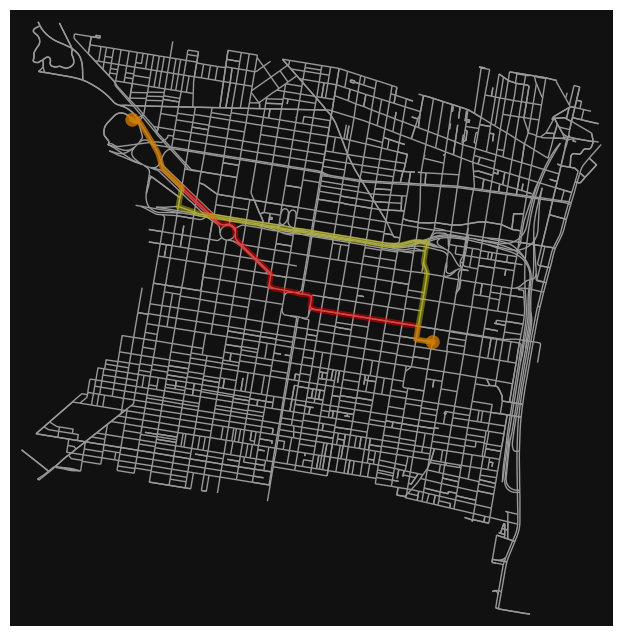

In [124]:
# plot the routes
fig, ax = ox.plot_graph_routes(
    G_cc,
    routes=[route1, route2],
    route_colors=["r", "y"],
    route_linewidth=6,
    node_size=0,
)

Let's plot both in an interactive map:

In [125]:
# m = ox.utils_graph.route_to_gdf(G_cc, route1, weight="length").explore(
#     tiles="cartodb dark matter",
#     color="red",
# )

# m = ox.utils_graph.route_to_gdf(G_cc, route2, weight="length").explore(
#     tiles="cartodb dark matter",
#     color="yellow",
#     m=m
# )


from osmnx import routing  # new location for route_to_gdf

# First route
gdf_route1 = routing.route_to_gdf(G_cc, route1, weight="length")
m = gdf_route1.explore(
    tiles="cartodb dark_matter",
    color="red"
)

# Second route on same map
gdf_route2 = routing.route_to_gdf(G_cc, route2, weight="length")
m = gdf_route2.explore(
    tiles="cartodb dark_matter",
    color="yellow",
    m=m
)

m

Let's compare to the two routes:

Distances:

In [126]:
# meters_to_miles = 0.0006213712

# # compare the two routes
# route1_length = (
#     ox.utils_graph.route_to_gdf(G_cc, route1, weight="length")["length"].sum()
#     * meters_to_miles
# )

# route2_length = (
#     ox.utils_graph.route_to_gdf(G_cc, route2, weight="length")["length"].sum()
#     * meters_to_miles
# )

import osmnx as ox
from osmnx import routing  # new module for route_to_gdf

meters_to_miles = 0.0006213712

# Compare the two routes
route1_length = (
    routing.route_to_gdf(G_cc, route1, weight="length")["length"].sum()
    * meters_to_miles
)

route2_length = (
    routing.route_to_gdf(G_cc, route2, weight="length")["length"].sum()
    * meters_to_miles
)

print(f"Route 1 length: {route1_length:.2f} miles")
print(f"Route 2 length: {route2_length:.2f} miles")

Route 1 length: 2.19 miles
Route 2 length: 2.46 miles


Travel times:

In [110]:
seconds_to_mins = 1.0 / 60

# route1_time = (
#     ox.utils_graph.route_to_gdf(G_cc, route1, weight="travel_time")["travel_time"].sum()
#     * seconds_to_mins
# )
# route2_time = (
#     ox.utils_graph.route_to_gdf(G_cc, route2, weight="travel_time")["travel_time"].sum()
#     * seconds_to_mins
# )

route1_time = (
    routing.route_to_gdf(G_cc, route1, weight="travel_time")["travel_time"].sum()
    * seconds_to_mins
)
route2_time = (
    routing.route_to_gdf(G_cc, route2, weight="travel_time")["travel_time"].sum()
    * seconds_to_mins
)


Summarize:

In [111]:
print(f"Route 1 is {route1_length:.2f} miles and takes {route1_time:.2f} minutes.")
print(f"Route 2 is {route2_length:.2f} miles and takes {route2_time:.2f} minutes.")

Route 1 is 2.19 miles and takes 5.18 minutes.
Route 2 is 2.46 miles and takes 4.57 minutes.


## Part 2:  Pandana

"Pandas Network Analysis - dataframes of network queries, quickly"

A complementary set of OSM-related features: 
- Downloading OSM-based networks
- Extracting amenity data (so-called "Points of Interest")
- Calculating network-constrained distances

- [GitHub](https://github.com/UDST/pandana)
- [Jupyter Notebook Examples](https://github.com/UDST/pandana/tree/master/examples)
- [Documentation](http://udst.github.io/pandana/)

In [4]:
# !pip install pandana

In [8]:
import pandana as pnda
from pandana.loaders import osm

### Step 1: Get amenity data

Key function: `osm.node_query()`

- This will extract amenities within a given bounding box.
- Similar to the `ox.features_from_bbox()` function in OSMnx, but we slightly different syntax.

In [9]:
osm.node_query?

Signature: osm.node_query(lat_min, lng_min, lat_max, lng_max, tags=None)
Docstring:
Search for OSM nodes within a bounding box that match given tags.

Parameters
----------
lat_min, lng_min, lat_max, lng_max : float
tags : str or list of str, optional
    Node tags that will be used to filter the search.
    See http://wiki.openstreetmap.org/wiki/Overpass_API/Language_Guide
    for information about OSM Overpass queries
    and http://wiki.openstreetmap.org/wiki/Map_Features
    for a list of tags.

Returns
-------
nodes : pandas.DataFrame
    Will have 'lat' and 'lon' columns, plus other columns for the
    tags associated with the node (these will vary based on the query).
    Index will be the OSM node IDs.
File:      /opt/anaconda3/envs/geospatial/lib/python3.13/site-packages/pandana/loaders/osm.py
Type:      function

Get the bounding box:

In [10]:
boundary = center_city_outline.bounds
boundary, type(boundary)

NameError: name 'center_city_outline' is not defined

In [11]:
[lng_min, lat_min, lng_max, lat_max] = boundary

NameError: name 'boundary' is not defined

In [7]:
# query OSM
poi_df = osm.node_query(lat_min, lng_min, lat_max, lng_max)

# remove missing data
poi_df = poi_df.dropna(subset=["amenity"])

NameError: name 'lat_min' is not defined

In [131]:
poi_df.head()

,lat,lon,railway,light_rail,name,network,operator,public_transport,wheelchair,highway,traffic_signals,direction,old_ref,ref,noref,crossing,crossing:markings,crossing:signals,traffic_calming,crossing:island,tactile_paving,stop,noexit,traffic_signals:direction,kerb,crossing:barrier,amenity,barrier,disused:railway,button_operated,crossing:markings:colour,traffic_signals:sound,traffic_signals:vibration,crossing_ref,supervised,railway:signal:direction,ele,gnis:feature_id,place,wikidata,wikipedia,alt_name,name:en,name:zh,brand,brand:wikidata,operator:wikidata,operator:wikipedia,short_name,addr:city,addr:housenumber,addr:postcode,addr:state,addr:street,air_conditioning,branch,cuisine,official_name,opening_hours,phone,takeaway,website,shop,ferry,building,atm,contact:facebook,diet:vegetarian,payment:cash,payment:credit_cards,payment:debit_cards,check_date,check_date:opening_hours,brand:website,healthcare,brewery,contact:instagram,diet:vegan,email,description,historic:amenity,note,education,old_name,leisure,sport,man_made,tower:type,operator:short,operator:type,operator:website,emergency,healthcare:speciality,railway:position,train,artwork_type,historic,tourism,information,artist_name,material,office,bench,bus,covered,network:wikidata,shelter,memorial,addr:housename,was:man_made,comment,historic:tourism,disused:leisure,was:name,was:opening_hours,was:sport,addr:country,platforms,station,subway,junction,iata,railway:ref,railway:switch:local_operated,railway:signal:position,bicycle,segregated,addr:unit,internet_access,internet_access:fee,start_date,subject:wikidata,drive_through,tram,contact:website,reservation,website:menu,contact:linkedin,contact:tiktok,contact:twitter,studio,delivery,indoor_seating,colour,parking,collection_times,self_service,check_date:kerb,entrance,screen,outdoor_seating,payment:coins,smoking,architect,disused:amenity,contact:phone,network:wikipedia,wikimedia_commons,female,dispensing,landmark,name:de,capacity,contact:myspace,fax,bar,designation,disused:shop,service:bicycle:pump,service:bicycle:repair,service:bicycle:retail,toilets:wheelchair,route_ref,source:pkey,vacant,fast_food,fuel:propane,power,substation,was:website,access,level,fee,museum,bin,lit,mobile,fuel:biodiesel,fuel:biogas,fuel:cng,fuel:diesel,fuel:e10,fuel:e85,fuel:electricity,collection_times:signed,ref:signed,check_date:collection_times,clothes,addr:full,check_date:diet:vegan,image:menu,image:menu:0,image:menu:1,image:menu:2,panoramax,panoramax:0,beauty,fair_trade,organic,fixme,check_date:diet:vegetarian,opening_hours:signed,bicycle_rental,kiosk,min_age,owner,owner:wikidata,ownership,payment:app,rental,sponsor,sponsor:wikidata,opening_hours:bar,opening_hours:kitchen,phone:mnemonic,disused:brand,disused:brand:wikidata,disused:brand:wikipedia,disused:dispensing,disused:drive_through,disused:healthcare,disused:opening_hours,denomination,religion,diet:pescetarian,lgbtq,fare_zone,toilets,toilets:access,power_supply,building:levels,population,payment:apple_pay,payment:cards,payment:contactless,second_hand,disused:name,farm_boxes,addr:place,social_facility,source:cuisine,demolished:amenity,demolished:opening_hours,demolished:phone,demolished:social_facility,maxheight,artwork_subject,inscription,access:delivery,wheelchair:description,wheelchair:description:en,was:cuisine,internet_access:ssid,elevation,park_ride,layer,artist:wikidata,height,name:es,service:bicycle:chain_tool,natural,name:fr,statue,cycleway:crossing:markings:colour,name:signed,surface,departures_board,subject:wikipedia,was:tourism,check_date:shelter,denotation,check_date:tactile_paving,maxspeed,facebook,was:brand,was:brand:wikidata,check_date:wheelchair,ref:isil,currency:USD,drink:coca-cola,drink:coke,drink:cola,drink:cola_zero,drink:soda,drink:water,vending,foot,locked,motor_vehicle,motorcar,year_of_construction,name:ru,toilets:unisex,kitchen_hours,animal,craft,contact:email,disused:cuisine,website:orders,website:reservation,source:lgbtq,horse,bottle,fountain,lamp_type,theatre:genre,line_attac

In [132]:
len(poi_df)

2918

In [133]:
poi_df[["lat", "lon", "amenity"]].head(10)

,lat,lon,amenity
id,,,
110237774,39.950401,-75.156620,parking_entrance
274216093,39.957640,-75.191254,atm
274217596,39.953015,-75.192289,cafe
313440966,39.963935,-75.166939,car_sharing
313440968,39.963978,-75.170407,car_sharing
326519551,39.944261,-75.132616,ferry_terminal
333786044,39.940858,-75.158928,restaurant
333786095,39.941924,-75.157357,cafe
333786448,39.942642,-75.157958,bank


#### Explore the amenities in this region

For the full list of amenities, see the [OSM Wikipedia](https://wiki.openstreetmap.org/wiki/Key:amenity)

In [134]:
import altair as alt  # Import Altair first

chart = (
    alt.Chart(poi_df)
    .mark_bar()
    .encode(y=alt.Y("amenity", sort="-x"), x="count()", tooltip=["amenity", "count()"])
)

chart

alt.Chart(...)

### Step 2: Create a Pandana network

- Key function: `pdna_network_from_bbox()` 
- It takes a bounding box and returns the OSM network within that region. 
- Multiple network types: 'walk' and 'drive'

In [132]:
# !pip install osmnet

In [135]:
net = osm.pdna_network_from_bbox(
    lat_min, lng_min, lat_max, lng_max, network_type="walk"
)

Requesting network data within bounding box from Overpass API in 1 request(s)
Posting to http://www.overpass-api.de/api/interpreter with timeout=180, "{'data': '[out:json][timeout:180];(way["highway"]["highway"!~"motor|proposed|construction|abandoned|platform|raceway"]["foot"!~"no"]["pedestrians"!~"no"](39.92862575,-75.19358245,39.97387241,-75.12593080);>;);out;'}"
Downloaded 9,611.8KB from www.overpass-api.de in 1.70 seconds
Downloaded OSM network data within bounding box from Overpass API in 1 request(s) and 1.78 seconds
Returning OSM data with 47,353 nodes and 16,063 ways...
Edge node pairs completed. Took 3.65 seconds
Returning processed graph with 23,280 nodes and 34,607 edges...
Completed OSM data download and Pandana node and edge table creation in 5.75 seconds
Generating contraction hierarchies with 12 threads.
Setting CH node vector of size 23280
Setting CH edge vector of size 34819
Range graph removed 962 edges of 69638
. 10% . 20% . 30% . 40% . 50% . 60% . 70% . 80% . 90% . 

### Step 3: Tell the network the location of amenities

Key function: `network.set_pois()`

- Today, we'll explore these four amenities: "restaurant", "bar", "school", "car_sharing"
- **IMPORTANT:** if you want to explore other amenities, you'll need to run the code below for your amenities of interest

In [136]:
# sensible defaults
max_distance = 2000  # in meters
num_pois = 10  # only need the 10 nearest POI to each point in the network


AMENITIES = ["restaurant", "bar", "school", "car_sharing"]
for amenity in AMENITIES:
    
    # get the subset of amenities for this type
    pois_subset = poi_df[poi_df["amenity"] == amenity]

    # set the POI, using the longitude and latitude of POI
    net.set_pois(
        amenity, max_distance, num_pois, pois_subset["lon"], pois_subset["lat"]
    )

In [137]:
# keyword arguments to pass for the matplotlib figure
bbox_aspect_ratio = (lat_max - lat_min) / (lng_max - lng_min)
fig_kwargs = {"facecolor": "w", "figsize": (10, 10 * bbox_aspect_ratio)}

# keyword arguments to pass for scatter plots
plot_kwargs = {"s": 20, "alpha": 0.9, "cmap": "viridis_r", "edgecolor": "none"}

### Step 4: Plot the walking distance to the nearest POI

For every point on the network, find the nth nearest POI, calculate the distance, and color that point according to the distance.

1. Use `network.nearest_poi()` to get distances from nodes to nearest POIs
1. Merge coordinates of network nodes with distances to nearest POIs
1. Plot the node coordinates, colored by distance to nth nearest POI

#### 4.1 Use `network.nearest_poi()` to get distances from nodes to nearest POIs

In [138]:
amenity = "bar"
access = net.nearest_pois(distance=2000, category=amenity, num_pois=num_pois)

In [139]:
access.tail(n=50)

,1,2,3,4,5,6,7,8,9,10
id,,,,,,,,,,
13182269961,717.754028,797.986023,798.521973,819.250977,879.151978,879.151978,913.083008,930.245972,1043.822021,1074.119019
13182269962,715.526001,795.757996,796.294006,817.023010,876.924011,876.924011,910.854980,928.018005,1041.593994,1071.890991
13182269963,639.046997,719.278992,719.815002,787.351013,834.375977,847.252014,847.252014,851.539001,1009.510010,1011.921997
13185110764,555.495972,556.807007,581.218994,660.169983,759.638000,1224.302979,1570.853027,1570.853027,1670.656006,1673.364990
13185150353,618.801025,667.177002,799.289978,823.702026,877.908997,1310.864990,1310.864990,1545.333008,1659.536987,1748.035034
13188965453,970.898987,973.130981,1021.692993,1021.692993,1025.203003,1025.203003,1025.203003,1027.494995,1027.562988,1040.069946
13189450687,247.828003,247.828003,247.828003,257.351990,257.351990,315.462006,470.367004,614.218994,614.672974,614.672974
13189450688,267.666992,275.649994,275.649994,275.649994,285.174011,285.174011,439.645996,566.877991,566.877991,597.903992
13189450689,238.880997,304.436005,304.436005,304.436005,313.959991,313.959991,440.773010,538.091980,538.091980,593.317017


#### 4.2 Merge coordinates of network nodes with distances to nearest POIs

In [140]:
net.nodes_df.head()

,x,y
id,,
103327043,-75.128666,39.934488
103332711,-75.128062,39.939224
103332730,-75.129329,39.941869
103333406,-75.130240,39.943351
103333412,-75.130346,39.943130


In [141]:
access.head()

,1,2,3,4,5,6,7,8,9,10
id,,,,,,,,,,
103327043,1752.093018,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0
103332711,988.283020,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0
103332730,670.846008,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0
103333406,597.504028,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0
103333412,630.221008,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0


In [142]:
import pandas as pd

# Merge the nodes and the distance to POIs
nodes = pd.merge(net.nodes_df, access, left_index=True, right_index=True)

# Make into a geodataframe
nodes = gpd.GeoDataFrame(
    nodes, geometry=gpd.points_from_xy(nodes["x"], nodes["y"]), crs="EPSG:4326"
)

In [143]:
nodes.head()

,x,y,1,2,3,4,5,6,7,8,9,10,geometry
id,,,,,,,,,,,,,
103327043,-75.128666,39.934488,1752.093018,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,POINT (-75.12867 39.93449)
103332711,-75.128062,39.939224,988.283020,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,POINT (-75.12806 39.93922)
103332730,-75.129329,39.941869,670.846008,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,POINT (-75.12933 39.94187)
103333406,-75.130240,39.943351,597.504028,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,POINT (-75.13024 39.94335)
103333412,-75.130346,39.943130,630.221008,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,POINT (-75.13035 39.94313)


#### 4.3 And now plot it!

Let's define a function to do this for us, since we'll repeat this plot multiple times

In [144]:
def plot_walking_distance(net, amenity, distance=1000, n=1):
    """
    Plot the walking distance to the specified amenity
    """
    from mpl_toolkits.axes_grid1 import make_axes_locatable

    # subset of POI
    poi_subset = poi_df[poi_df["amenity"] == amenity]

    # get the distances to nearest num_pois POI
    access = net.nearest_pois(distance=1000, category=amenity, num_pois=num_pois)

    # merge node positions and distances to nearest PO
    nodes = pd.merge(net.nodes_df, access, left_index=True, right_index=True)
    nodes = gpd.GeoDataFrame(
        nodes, geometry=gpd.points_from_xy(nodes["x"], nodes["y"]), crs="EPSG:4326"
    )

    # Create the figure
    fig, ax = plt.subplots(figsize=(10, 10))
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.1)

    # plot the distance to the nth nearest amenity
    ax = nodes.plot(ax=ax, cax=cax, column=nodes[n], legend=True, **plot_kwargs)

    # add the amenities as stars
    for i, row in poi_subset.iterrows():
        ax.scatter(row["lon"], row["lat"], color="red", s=100, marker="*")

    # format
    ax.set_facecolor("black")
    ax.figure.set_size_inches(fig_kwargs["figsize"])

    # set extent
    [xmin, ymin, xmax, ymax] = nodes.geometry.total_bounds
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    return ax

### Evaluating amenity choice

The difference between maps to the nearest amenity and for example, the 5th nearest amenity tells us about the options consumers have

#### Example: bars

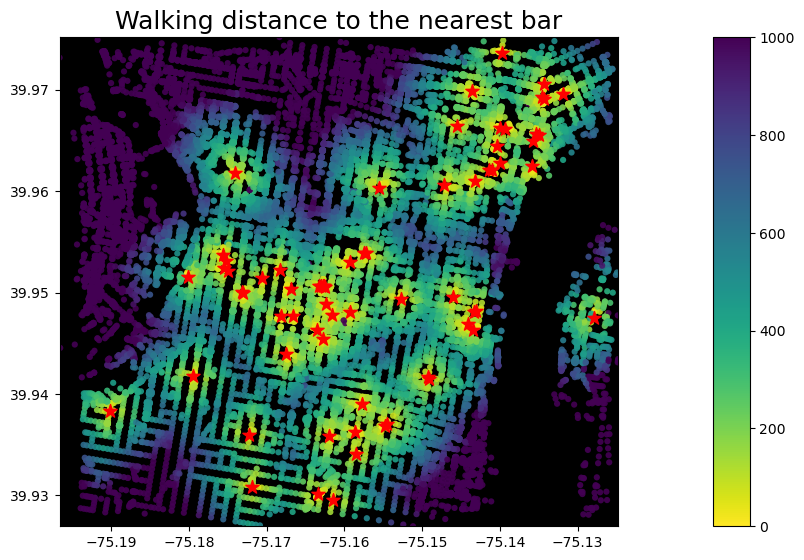

In [145]:
ax = plot_walking_distance(net, "bar", n=1)
ax.set_title("Walking distance to the nearest bar", fontsize=18);

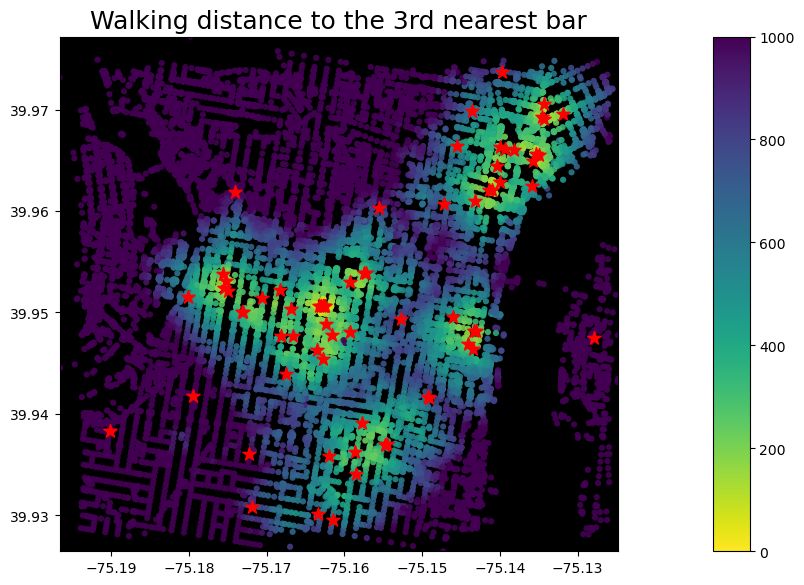

In [147]:
ax = plot_walking_distance(net, "bar", n=3)
ax.set_title("Walking distance to the 3rd nearest bar", fontsize=18);

#### Example: schools

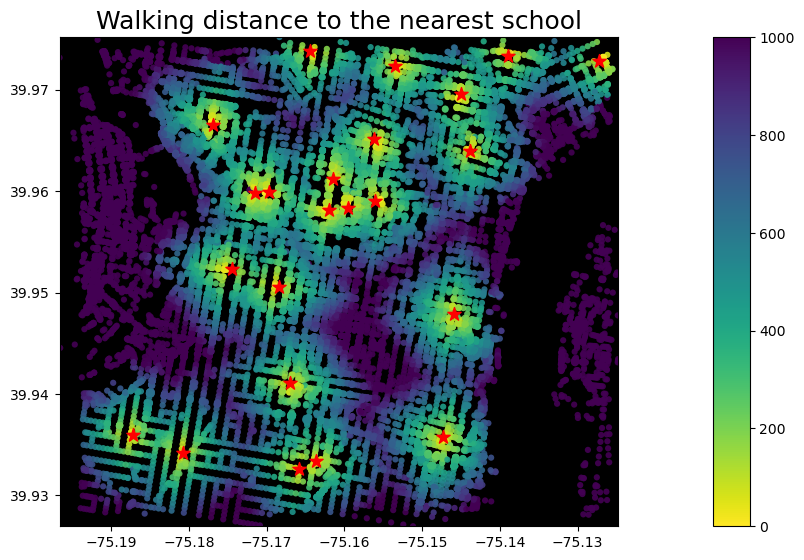

In [146]:
ax = plot_walking_distance(net, "school", n=1)
ax.set_title("Walking distance to the nearest school", fontsize=18);

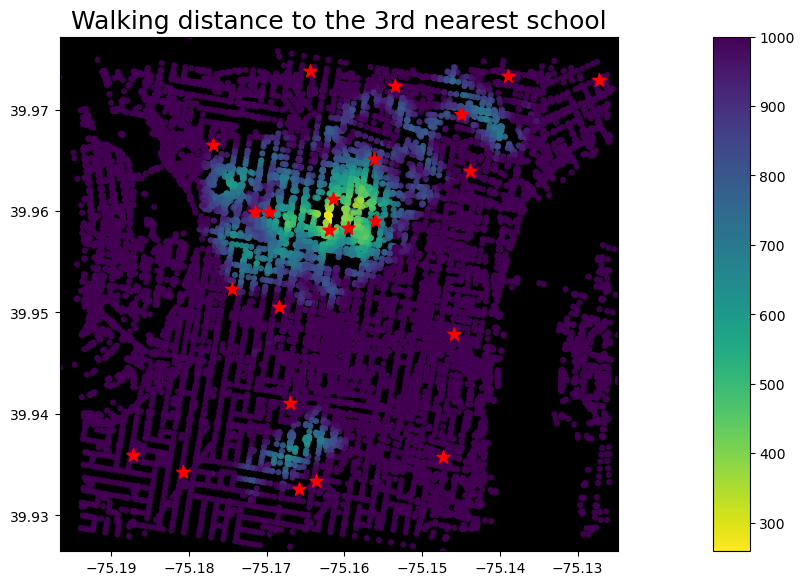

In [149]:
ax = plot_walking_distance(net, "school", n=3)
ax.set_title("Walking distance to the 3rd nearest school", fontsize=18);

#### Example: restaurants

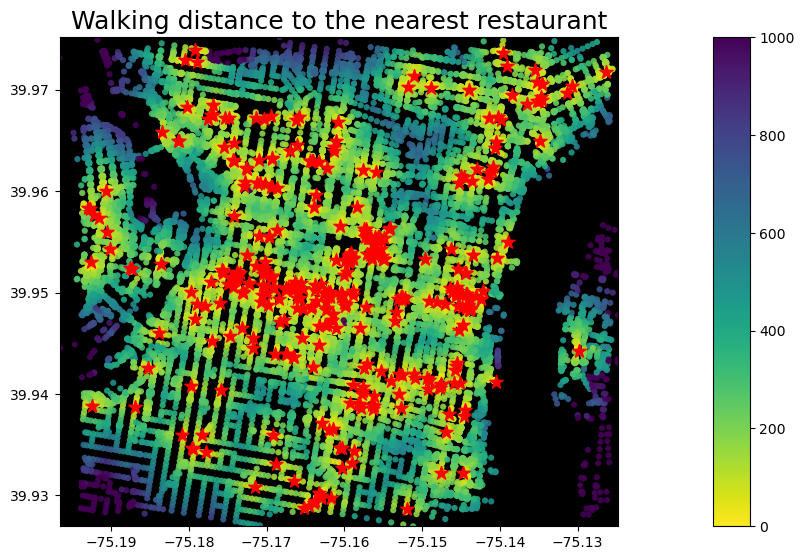

In [147]:
ax = plot_walking_distance(net, "restaurant", n=1)
ax.set_title("Walking distance to the nearest restaurant", fontsize=18);

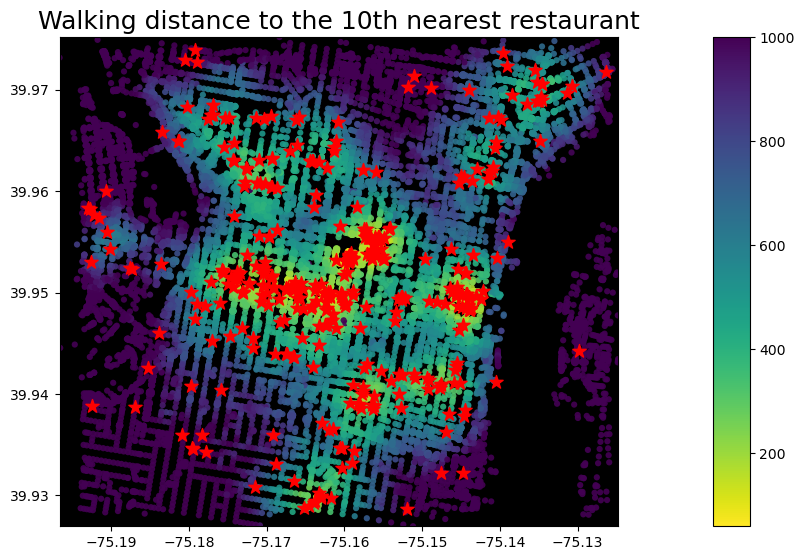

In [148]:
ax = plot_walking_distance(net, "restaurant", n=10)
ax.set_title("Walking distance to the 10th nearest restaurant", fontsize=18);

#### Example: car sharing

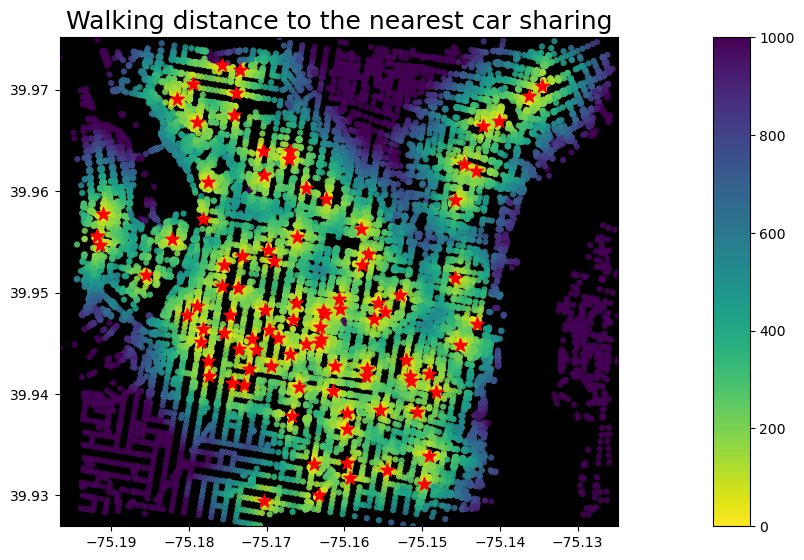

In [149]:
ax = plot_walking_distance(net, "car_sharing", n=1)
ax.set_title("Walking distance to the nearest car sharing", fontsize=18);

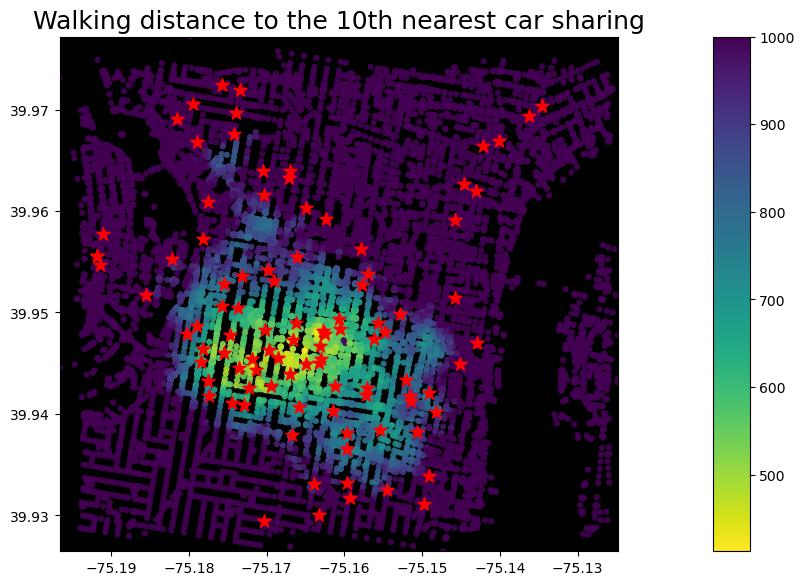

In [153]:
ax = plot_walking_distance(net, "car_sharing", n=10)
ax.set_title("Walking distance to the 10th nearest car sharing", fontsize=18);

## At-home exercise: Explore amenities in the neighborhood of your choice

Many, many more amenities are logged throughout the city. Pick your favorite neighborhood and explore. 

See [this page](https://wiki.openstreetmap.org/wiki/Key:amenity) for the full list of amenities.

**Final project idea**: With this kind of analysis, you can look at amenity-based influence in housing, neighborhood selection, etc. or something similar to the [Walk Score](https://www.walkscore.com/).